# ¿Qué información corresponde a un pronóstico al momento de emitirlo?

**Pregunta:** ¿Por qué el mismo extracto eléctrico puede dar una elección histórica, una clasificación del bloque final y una trayectoria de cobertura diferentes?

## Objetivos

Un tablero puede mostrar un método preferido, una trayectoria para un origen concreto y una estimación de cobertura reciente en la misma pantalla. Las tres cantidades usan observaciones distintas y responden preguntas diferentes. Las reproduciremos siguiendo la información disponible en cada cálculo. El experimento también permite distinguir una exportación didáctica pequeña de una entrega completa del producto.

El caso usa un extracto cronológico del medidor MT_010 de la colección eléctrica de UCI. Sus valores horarios suman las mediciones de cuarto de hora retenidas. Reservamos las últimas 24 observaciones de un extracto de cinco días y usamos observaciones anteriores para la evaluación histórica. La prueba de orígenes móviles, el pronóstico del día reservado y la reproducción paso a paso comparten la fuente y usan orígenes distintos. Ninguna representa un resultado nuevo de planificación para un cliente. Conservaremos sus resultados por separado incluso cuando compartan el nombre de un método.

## Preparación

Use el entorno declarado para los cuadernos. El registro de etapas descubre adaptadores opcionales entre las bibliotecas instaladas. El conjunto disponible puede diferir del conjunto completo publicado. La celda muestra los adaptadores que efectivamente se ejecutan. Este entorno no descarga pesos de modelos. Las versiones fijadas permiten identificar las implementaciones locales y sus bibliotecas de referencia.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
```


In [1]:
# Inicializa el entorno fijado sin descargar datos de entrada.
from pathlib import Path
import importlib.metadata
import json
import sys
from tempfile import TemporaryDirectory
from time import perf_counter
import warnings
import numpy as np
import matplotlib.pyplot as plt
from preqts import SeasonalNaive
root = next(path for path in Path.cwd().parents if (path / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab import registry
from chronoscopelab.core.manifest import build_index
from chronoscopelab.io.formats import write_json
from chronoscopelab.io.schema import SeriesSpec
from chronoscopelab.model.forecasters import classical_forecasters, forecast_all
from chronoscopelab.reevaluation import metrics
from chronoscopelab.stages import analyze, evaluate, export, feature_extraction, infer, preprocess, streaming, train
plt.rcParams.update({"figure.figsize": (8, 3.2), "figure.dpi": 95, "font.size": 10})
print("PreqTS", importlib.metadata.version("preqts"))


PreqTS 0.3.0


## Datos

La ingestión lee una tabla larga con identidad de serie y fecha como claves. Devuelve registros aceptados, rechazados y observaciones marcadas. Una marca distingue una observación sospechosa de una serie ilegible o inadmisible. Un registro aceptado todavía puede contener faltantes conforme a la política de ingreso. Antes de ajustar un modelo hacen falta condiciones adicionales para usar un prefijo contiguo y finito. El extracto de este ejemplo satisface esas condiciones. Se corta en orden temporal y conserva las posiciones originales, de modo que el rezago 24 corresponde a un día.


In [2]:
# Admite la tabla larga y conserva un extracto cronológico contiguo.
table = preprocess.run(str(root / "data/examples/electricity_sample.csv"))
case = registry.get_case("REAL_electricity")
record = table.accepted[0]
spec = SeriesSpec(case.id, tuple(record.y[:120]), 24, case.horizon, "H", case.source)
levels = (0.1, 0.5, 0.9)
prefix, target = infer.split(spec)
fitting = SeriesSpec(case.id, tuple(prefix), spec.seasonality, spec.horizon, "H", case.source)
print("Ingestión", table.summary())
print("Serie, filas de ajuste, filas reservadas:", record.unique_id, len(prefix), len(target))


Ingestión 1 accepted, 0 rejected, 0 flagged
Serie, filas de ajuste, filas reservadas: MT_010 96 24


El código parte de un registro y fija el horizonte antes de llamar a las funciones de puntuación. La etapa de inferencia reserva el último bloque, ajusta el prefijo anterior y devuelve las predicciones. Los objetivos se entregan a la puntuación y a la exportación. La misma separación se aplica a los diagnósticos que informan una decisión. Un gráfico retrospectivo puede usar la serie completa para explicar lo ocurrido. Un diagnóstico empleado para elegir un pronóstico requiere solo información disponible en el momento de emisión.

## Método

Ejecute las etapas de características y diagnóstico sobre el prefijo de ajuste. La fila de características conserva cantidades como la correlación de rezago uno en una representación compacta. Describe los datos entregados a la etapa y por sí misma no predice la próxima observación. El registro de análisis agrega paneles cuya aplicabilidad varía. Algunos métodos eliminan observaciones no finitas o requieren dependencias opcionales. Un panel con error o motivo de omisión se interpreta como indisponible. La celda imprime las identidades de los paneles para hacer visible esa frontera.


In [3]:
# Entrega solo el prefijo de ajuste a las etapas descriptivas.
with warnings.catch_warnings(record=True):
    warnings.simplefilter("always")
    features = feature_extraction.run(fitting)
    analysis = analyze.run(fitting, seed=42)
print("Media y correlación de rezago uno:", round(features.mean, 4), round(features.acf1, 4))
print("Paneles analizados:", ", ".join(sorted(analysis)))


Media y correlación de rezago uno: 282.9973 0.8825
Paneles analizados: autocorrelation, causality, changepoints, distribution, filters, fractal, n, nonlinear, seasonality, seasonality_period, sequence, stationarity, volatility


Una predicción puntual desde el origen final se compara con el objetivo reservado del mismo paso. Sean $n$ la longitud del prefijo, $h$ el horizonte y $m$ el rezago estacional. La escala se calcula una vez usando solo el prefijo.

$$
s_m=\frac{1}{n-m}\sum_{i=m+1}^{n}|y_i-y_{i-m}|.
$$

El MASE del bloque final para una trayectoria puntual $\widehat y$ es

$$
\operatorname{MASE}=\frac{1}{h s_m}\sum_{j=1}^{h}|y_{n+j}-\widehat y_{n+j}|.
$$

El denominador mide la variación pasada respecto a la recurrencia estacional. Un valor pequeño puede amplificar errores de tamaño absoluto moderado. El código usa la misma escala del prefijo para todas las trayectorias finales y permite compararlas directamente en ese origen. El evaluador histórico usa su propia escala prequential para un conjunto anterior de orígenes. Comparar las clasificaciones permite diagnosticar sensibilidad al diseño de evaluación. La diferencia de puntajes no estima una degradación medida sobre varios bloques independientes.

## Comparación

La referencia del paquete repite la fase del último día y devuelve tres columnas de cuantiles. Su mediana coincide con el valor registrado en la fase correspondiente para estos 24 pasos. La trayectoria Theta proviene de la etapa de inferencia instalada. La banda corresponde a sus cuantiles inferior y superior, y la línea observada se dibuja después del ajuste. Compare los recorridos durante las subidas y caídas del día. Un error medio puede ocultar un máximo desplazado o una respuesta tardía a una caída.


Adaptadores disponibles: SeasonalNaive, SES, Holt, HoltWinters, Theta, AutoETS, AutoTheta, AutoARIMA, LightGBM, ContextMemory
Tipos de avisos numéricos: ['TqdmWarning', 'UserWarning']


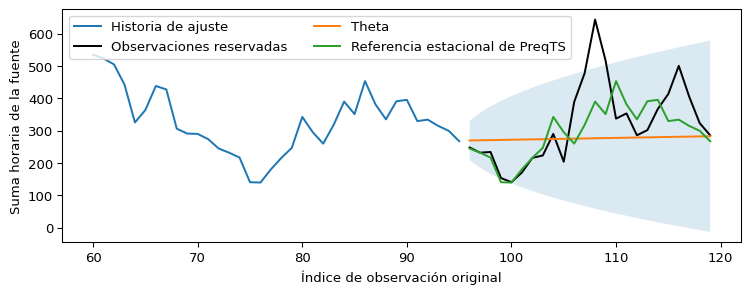

In [4]:
# Pronostica el bloque final y ejecuta la referencia del mismo origen.
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    forecast = infer.run(spec, levels)
print("Adaptadores disponibles:", ", ".join(row.name for row in forecast.methods))
print("Tipos de avisos numéricos:", sorted({type(w.message).__name__ for w in notices}))
theta = next(method for method in forecast.methods if method.name == "Theta")
reference = SeasonalNaive(seasonality=spec.seasonality)
reference.start(np.asarray(prefix))
ref = np.asarray(reference.predict(spec.horizon, list(levels)))
assert np.array_equal(ref[:, 1], prefix[-spec.seasonality:][:spec.horizon])
fig, ax = plt.subplots()
indices = np.arange(len(prefix), len(spec.y))
ax.plot(np.arange(len(prefix))[-36:], prefix[-36:], label="Historia de ajuste")
ax.plot(indices, target, color="black", label="Observaciones reservadas")
ax.plot(indices, theta.point, label="Theta")
ax.plot(indices, ref[:, 1], label="Referencia estacional de PreqTS")
ax.fill_between(indices, theta.lower, theta.upper, alpha=0.16)
ax.set(xlabel="Índice de observación original", ylabel="Suma horaria de la fuente")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()


La figura siguiente compara los puntajes históricos y del bloque final de SeasonalNaive, SES, Holt, HoltWinters y Theta. El evaluador histórico ajusta orígenes anteriores dentro del prefijo y puntúa allí los bloques posteriores correspondientes. Los adaptadores pueden tener presupuestos históricos distintos, por lo que la figura compara solo estas cinco implementaciones. Para cada una el bloque final contiene un patrón particular de objetivos. Un método con poco error en orígenes anteriores puede encontrar otro nivel diario o una fase distinta en el bloque reservado. Identifique el método con la menor barra de cada evaluación e informe el diseño temporal junto con la clasificación.


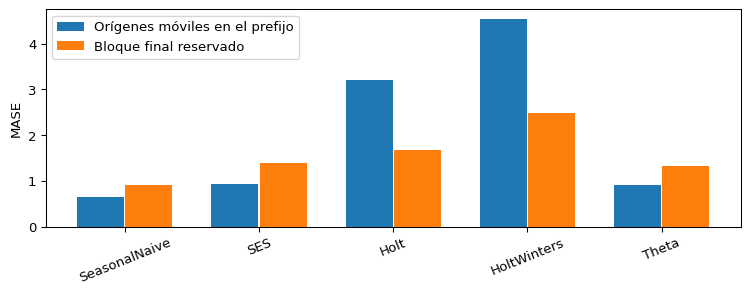

Selección con orígenes móviles: SeasonalNaive


In [5]:
# Distingue puntajes históricos de errores del bloque final.
historical = evaluate.run(spec, levels, classical_forecasters())
eligible = [row for row in forecast.methods if row.name in historical["methods"]]
final = [metrics(prefix, target, row.point, row.lower, row.upper, spec.seasonality)["mase"]
         for row in eligible]
fig, ax = plt.subplots()
positions = np.arange(len(eligible))
ax.bar(positions - 0.18, [historical["methods"][row.name]["mase"] for row in eligible],
       width=0.35, label="Orígenes móviles en el prefijo")
ax.bar(positions + 0.18, final, width=0.35, label="Bloque final reservado")
ax.set_xticks(positions, [row.name for row in eligible], rotation=22)
ax.set(ylabel="MASE")
ax.legend()
fig.tight_layout()
plt.show()
print("Selección con orígenes móviles:", historical["best_method"])


### Sensibilidad a la ventana de evaluación

Una reproducción separada de un paso se mantiene dentro del mismo prefijo de ajuste. En cada paso el pronosticador predice antes de ver el resultado siguiente. El controlador puede modificar su próximo intervalo después de conocer si el actual cubrió la observación. Ese orden define el significado de un intervalo adaptativo. Las predicciones vecinas siguen siendo dependientes. La tabla histórica y la trayectoria de cobertura también tienen horizontes diferentes, así que este cálculo no establece cobertura para la banda de 24 pasos.


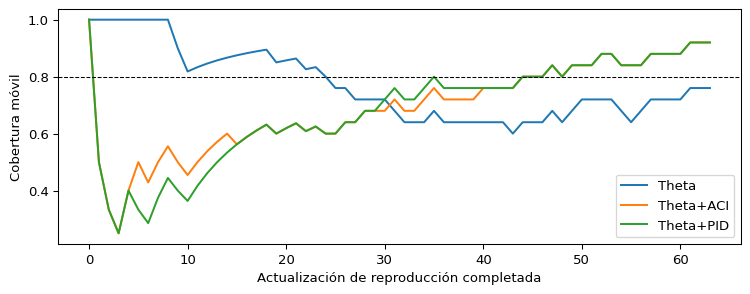

In [6]:
# Reproduce pronósticos de un paso dentro de la historia de ajuste.
replay = streaming.run(fitting)
fig, ax = plt.subplots()
for name in ("Theta", "Theta+ACI", "Theta+PID"):
    row = replay["methods"][name]
    ax.plot(row["rolling_coverage"], label=name)
ax.axhline(replay["nominal_coverage"], linestyle="--", color="black", linewidth=0.8)
ax.set(xlabel="Actualización de reproducción completada", ylabel="Cobertura móvil")
ax.legend()
fig.tight_layout()
plt.show()


La línea discontinua indica el objetivo marginal declarado. Cuando una curva se aproxima al objetivo, observe cuánto dura esa cercanía y qué ocurrió antes. Un intervalo amplio puede obtener cobertura alta. Una puntuación de intervalos adecuada equilibra amplitud y observaciones que quedan fuera. Las trayectorias no cuantifican incertidumbre sobre una fracción de cobertura futura. Permiten ver cuándo responde un controlador a una secuencia de fallos en este prefijo. El adaptador de un paso reajusta el pronóstico con la historia disponible. El tiempo de ese adaptador es distinto del tiempo para actualizar un estimador con estado persistente nativo.

## Resultados

**Respuesta:** La clasificación histórica resume orígenes anteriores dentro de las 96 observaciones disponibles. La clasificación final usa las 24 observaciones reservadas. La cobertura móvil usa actualizaciones de un paso dentro del prefijo. Los valores cambian cuando cambian los orígenes, horizontes y observaciones disponibles. Interprete cada salida con su propia ventana objetivo y denominador.

El selector de entrenamiento de la siguiente celda usa dos historias generadas. Promedia el MASE histórico de cada uno de los mismos cinco pronosticadores en esas historias y registra un método por defecto. No utiliza los objetivos eléctricos ni elige al ganador del día eléctrico. La exportación escribe una trayectoria, un manifiesto, un análisis y una reproducción en un directorio temporal. Registra el costo medido de la llamada de pronóstico de los cinco adaptadores en esa ejecución, sin imprimirlo como resultado reproducible de otra máquina. El manifiesto guarda una ruta y un tamaño en bytes. El índice identifica el manifiesto de cada caso. Se comprueba esa relación antes de retirar el directorio temporal.


In [7]:
# Entrena sobre historias distintas y crea un índice temporal.
training = [registry.build_series(registry.get_case(name), seed=42)
            for name in ("TRND_seasonal", "SEAS_hourly")]
start = perf_counter()
forecast_all(prefix, spec.seasonality, spec.horizon, levels)
elapsed_ms = (perf_counter() - start) * 1000
with TemporaryDirectory() as directory:
    output = Path(directory)
    selector = train.run(training, str(output / "models"), levels)
    manifest = export.run(case=case, feature=features, result=forecast, actual=target.tolist(),
                          eval_metrics=historical, seed=42, run_ms=elapsed_ms, flags=table.flagged,
                          derived_dir=directory, manifests_dir=str(output / "manifests"),
                          analysis=analysis, streaming_bench=replay)
    path = output / manifest["artifact"]["path"]
    assert path.stat().st_size == manifest["artifact"]["bytes"]
    trace = json.loads(path.read_text(encoding="utf-8"))
    assert trace["history_len"] == len(prefix) and trace["horizon"] == len(target)
    index = build_index([{"case_id": case.id, "category": case.category,
                          "manifest_path": f"manifests/{case.id}.json"}])
    write_json(output / "manifests/index.json", index)
print("Tamaño del índice temporal:", index["n_cases"],
      "método por defecto del entrenamiento:", selector["default_method"])


Tamaño del índice temporal: 1 método por defecto del entrenamiento: HoltWinters


El inventario de una entrega utiliza las mismas relaciones de archivos para todo el producto. Una trayectoria bien formada por sí sola no demuestra que la aplicación tenga cada caso o evidencia declarada. El registro de disponibilidad identifica el resumen criptográfico del catálogo y su versión. El índice admitido conserva el total de casos. Las validaciones de esquema, vinculaciones numéricas y comprobaciones de cohortes completas acompañan al registro. Lea el inventario y sus identidades por separado del pequeño ejercicio de entrenamiento.


In [8]:
# Lee los totales de casos y contratos del inventario completo.
current = json.loads((root / "data/derived/readiness.json").read_text(encoding="utf-8"))
admitted = json.loads((root / "data/derived/manifests/index.json").read_text(encoding="utf-8"))
print("Tamaño del índice admitido:", admitted["n_cases"], "entradas de disponibilidad:", len(current["contracts"]))
print("Resumen criptográfico del catálogo:", current["catalog_sha256"],
      "versión del producto:", current["product_version"])


Tamaño del índice admitido: 15 entradas de disponibilidad: 15
Resumen criptográfico del catálogo: 867d58642d93ad3df83ee1b29207549f2ccafb0050291995f92332d9b17477e8 versión del producto: 0.26.000


### Identifique el origen de un puntaje publicado

La comparación nueva completa tiene una fila eléctrica con el mismo identificador de caso y horizonte. Usa el bloque final de la historia admitida completa. El corte didáctico usa un día anterior, por lo que identificar el caso y el horizonte no basta para establecer que los objetivos coinciden. Compare longitudes y objetivos antes de trasladar un puntaje. El estudio externo de combinaciones agrega otro nivel de identidad. Su índice apunta a una serie concreta y su registro de caso contiene orígenes elegibles con resúmenes de prefijos, escalas, objetivos y trayectorias. Siga una entrada del índice e interprete la forma de la primera trayectoria ValidationMix como observaciones reservadas por niveles de cuantil. El índice compacto permite navegar. El registro de caso aporta lo necesario para examinar un resultado numérico de la serie.


In [9]:
# Identifica los orígenes antes de comparar puntajes publicados.
derived = root / "data/derived"
fresh = json.loads((derived / "fresh-reevaluation.json").read_text(encoding="utf-8"))
released = next(row for row in fresh["cases"] if row["case_id"] == case.id)
combination_index = json.loads((derived / "validated-combinations.json").read_text(encoding="utf-8"))
entry = next(row for row in combination_index["cases"]
             if (row["dataset"], row["id"]) == ("m4_weekly", "T1"))
combination_case = json.loads((derived / entry["path"]).read_text(encoding="utf-8"))
first = combination_case["origins"][0]
mix = next(method for method in first["methods"] if method["name"] == "ValidationMix")
print("Longitud de ajuste eléctrico publicado:", released["history_length"])
print("Primer objetivo eléctrico didáctico y publicado:", target[0], released["actual"][0])
print("Serie externa, primer corte, longitud reservada:", entry["id"], first["origin"], len(first["actual"]))
print("Dimensiones de la trayectoria ValidationMix:", np.asarray(mix["quantiles"]).shape)


Longitud de ajuste eléctrico publicado: 456
Primer objetivo eléctrico didáctico y publicado: 248.3871 237.6344
Serie externa, primer corte, longitud reservada: T1 2153 13
Dimensiones de la trayectoria ValidationMix: (13, 3)


El experimento del navegador emplea otra frontera. El grafo lineal congelado recibe un prefijo normalizado de longitud fija y produce doce valores puntuales. El estudio inicial con cresta cambió el estimador puntual. La confirmación conserva el grafo y los puntos y cambia solo los intervalos. Recalcule los estudios retenidos antes de comparar errores normalizados. El verificador independiente comprueba el resumen del grafo, la identidad de configuraciones, la separación de particiones y la aritmética sobre trayectorias retenidas. Este cálculo usa sus salidas guardadas y no reajusta el grafo ni mide otro tiempo de navegador.


In [10]:
# Recalcula dos estudios antes de interpretar cambios de intervalos.
sys.path.insert(0, str(root / "scripts"))
from check_browser_linear_evidence import validate
validated = validate(root)
print("Estudios recalculados de forma independiente:", [study["study"] for study in validated])
browser = root / "docs/research/browser-linear"
ridge = json.loads((browser / "v1/results.json").read_text(encoding="utf-8"))["scores"]["all"]
confirmed = json.loads((browser / "confirmation-v1/results.json").read_text(encoding="utf-8"))["scores"]["all"]
metadata = json.loads((root / "frontend/public/models/nlinear.json").read_text(encoding="utf-8"))
print("Historia y horizonte del grafo congelado:", metadata["lookback"], metadata["horizon"])
print("MAE puntual, congelado y cresta:", [round(row["normalized_mae"], 4) for row in ridge.values()])
print("Puntuaciones de intervalos en confirmación:", {name: round(row["normalized_interval_score"], 4)
                                         for name, row in confirmed.items()})


Estudios recalculados de forma independiente: ['v1', 'confirmation-v1']
Historia y horizonte del grafo congelado: 48 12
MAE puntual, congelado y cresta: [0.5141, 0.518, 1.0645]
Puntuaciones de intervalos en confirmación: {'gaussian': 4.749, 'global': 2.8038, 'stratified': 2.3934}


En el estudio de cresta, compare primero el MAE puntual con el modelo congelado. Un intervalo más estrecho puede mejorar su puntuación aunque empeore el centro. En la confirmación compare las puntuaciones de intervalos con la misma trayectoria puntual. El grupo de calibración depende de la rugosidad dentro del prefijo observado. Sus radios residuales empíricos se calculan con series separadas de calibración y se puntúan sobre series generadas reservadas. Una puntuación normalizada se expresa respecto a la escala del prefijo. No corresponde a un error en unidades eléctricas, y la prueba sintética no establece la cobertura del medidor del ejemplo.

### Repite la comparación con tus propios datos

Elija un horizonte que corresponda a una acción, como asignar personal para el siguiente turno. Preserve fechas y frecuencia de muestreo, incluidas transiciones de hora legal. Declare el tratamiento de huecos y fechas repetidas antes de ingerir la tabla. Use historias separadas para entrenar un método por defecto cuando estén disponibles. Reserve los bloques finales antes de puntuar. Mantenga el prefijo contiguo y decida si el controlador recibe los objetivos de inmediato o con retraso. Aplique la misma condición a cada método comparado.

Si hay historia suficiente, examine ambos diseños de evaluación sobre varios días reservados sucesivos. Guarde la trayectoria completa de cada día, la revisión del método y sus unidades. Cuando un adaptador no pueda pronosticar un origen, informe el fallo y analice explícitamente los orígenes comunes. Conserve los registros largos disponibles y sus resúmenes versionados, de modo que un lector pueda recuperar las observaciones de cada resultado. Antes de publicar una exportación, compruebe los derechos de redistribución de la serie y revise si las predicciones o diagnósticos por paso revelan valores restringidos.

## Resumen

Identifique primero los orígenes y los conjuntos de información. Elija un puntaje apropiado para el horizonte de decisión, conserve pronósticos y objetivos, y documente las historias de entrenamiento y los métodos disponibles. La trayectoria y el manifiesto permiten inspeccionar estas decisiones. Las comprobaciones de inventario y evidencia determinan si una entrega completa está lista.

## Referencias

- [Fuente eléctrica de UCI](https://doi.org/10.24432/C58C86).
- [Evaluación prequential de Dawid](https://doi.org/10.2307/2981683).
- [Inferencia conforme adaptativa](https://arxiv.org/abs/2106.00170).
- [PreqTS 0.3.0](https://pypi.org/project/preqts/0.3.0/).
